<a href="https://colab.research.google.com/github/phann0818/carbon_footprint/blob/main/rd2026_visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [84]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, HTML

In [85]:
# Mount Google Drive
drive.mount('/content/drive')

training_file = '/content/drive/MyDrive/rd2026_visualization/training.json'

with open(training_file, 'r') as t:
    data = json.load(t)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [86]:
all_defined_stds = set(data['standards_definitions'].keys())
rows = []
hard_rows = []
for book in data.get('titles', []):
    for chapter in book.get('items', []):
        for cluster in chapter.get('clusters', []):
            for item in cluster.get('items', []):
                hard_rows.append({
                    'type': item.get('type'),
                    'has_url': 'Yes' if item.get('url') else 'No'
                })
complexity_rows = []
for book in data.get('titles', []):
    for chapter in book.get('items', []):
        for cluster in chapter.get('clusters', []):
            for item in cluster.get('items', []):
                stds = item.get('standards', [])
                complexity_rows.append({
                    'type': item.get('type'),
                    'std_count': len(stds) if stds else 0
                })

df_comp = pd.DataFrame(complexity_rows)

df_hard = pd.DataFrame(hard_rows)
used_counts = {}
total_assignments = 0

In [87]:
# Flattening the hierarchy
for book in data.get('titles', []):
    book_name = book.get('title')
    for chapter in book.get('items', []):
        for cluster in chapter.get('clusters', []):
            for item in cluster.get('items', []):
                stds = item.get('standards', [])
                rows.append({'book': book_name, 'type': item.get('type'), 'standards': stds})
                for s in stds:
                    used_counts[s] = used_counts.get(s, 0) + 1
                    total_assignments += 1

df = pd.DataFrame(rows)
df_exploded = df.explode('standards')

In [88]:
for book in data.get('titles', []):
    book_name = book.get('title')
    for chapter in book.get('items', []):
        for cluster in chapter.get('clusters', []):
            for item in cluster.get('items', []):
                stds = item.get('standards', [])
                rows.append({'book': book_name, 'type': item.get('type'), 'standards': stds})
                for s in stds:
                    used_counts[s] = used_counts.get(s, 0) + 1
                    total_assignments += 1

df = pd.DataFrame(rows)
df_exploded = df.explode('standards')

# Standardized Variables for Table and Graphs
total_def = len(all_defined_stds)
used_count = len(used_counts)
unused_count = total_def - used_count
max_val = max(used_counts.values()) if used_counts else 0

In [89]:
# Summary Table
summary_df = pd.DataFrame({
    'Metric': [
        'Total Standards Defined',
        'Standards with Contribution',
        'Standards without Contribution',
        'Max Frequency (Single Standard)'
    ],
    'Value': [total_def, used_count, unused_count, max_val],
    'Percentage (%)': [
        '100.0%',
        f"{(used_count/total_def)*100:.1f}%",
        f"{(unused_count/total_def)*100:.1f}%",
        f"{(max_val/total_assignments)*100:.1f}% of labels"
    ]
})

display(HTML("<h2 style='text-align: center;'>📊 DATA SUMMARY TABLE 📊</h2>"))

display(HTML(f"""
<div style="display: flex; justify-content: center;">
    {summary_df.to_html(index=False)}
</div>
"""))

Metric,Value,Percentage (%)
Total Standards Defined,173,100.0%
Standards with Contribution,97,56.1%
Standards without Contribution,76,43.9%
Max Frequency (Single Standard),42,3.8% of labels


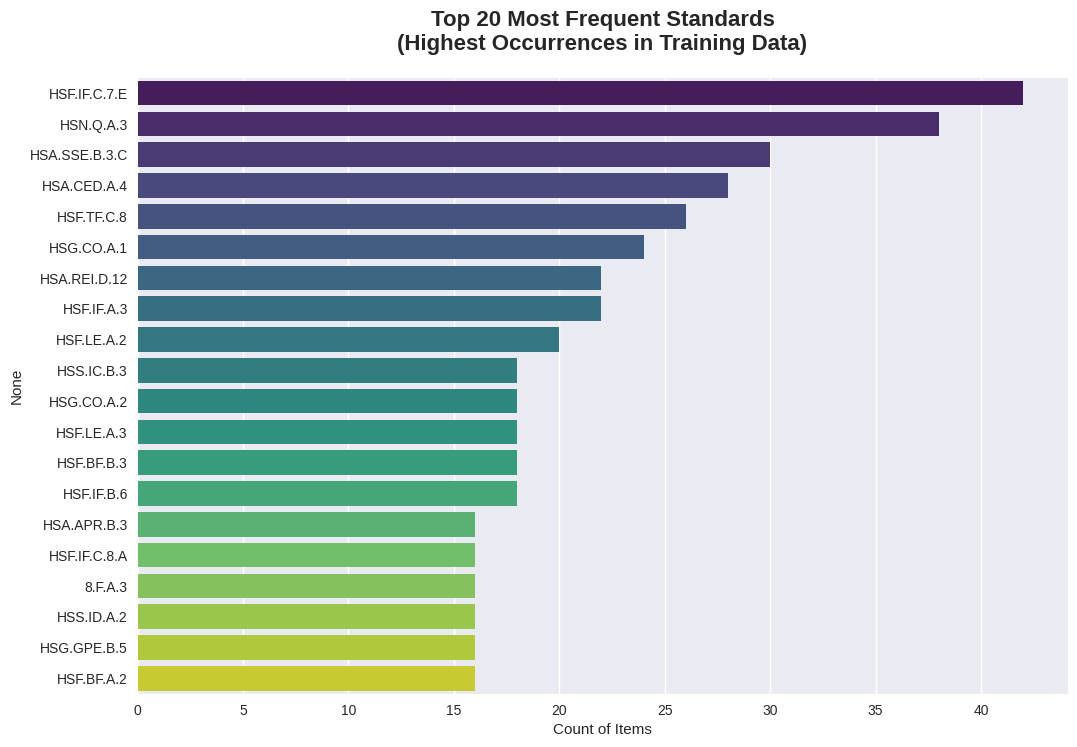

In [90]:
# Visualization
plt.style.use('seaborn-v0_8')

# Graph 1: Top 20 Standards
plt.figure(figsize=(12, 8))
top_20 = pd.Series(used_counts).sort_values(ascending=False).head(20)
sns.barplot(x=top_20.values, y=top_20.index, hue=top_20.index, palette='viridis', legend=False)
plt.title('Top 20 Most Frequent Standards\n(Highest Occurrences in Training Data)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Count of Items')
plt.show()

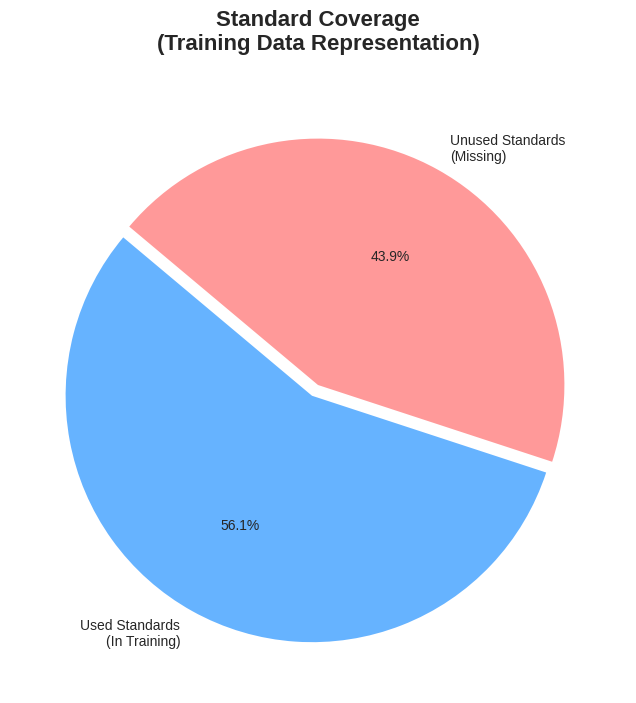

In [91]:
# Graph 2: Coverage Pie
plt.figure(figsize=(10, 8))
plt.pie([used_count, unused_count],
        labels=['Used Standards\n(In Training)', 'Unused Standards\n(Missing)'],
        autopct='%1.1f%%', colors=['#66b3ff', '#ff9999'], startangle=140, explode=(0.05, 0))
plt.title('Standard Coverage\n(Training Data Representation)', fontsize=16, fontweight='bold', pad=20)
plt.show()

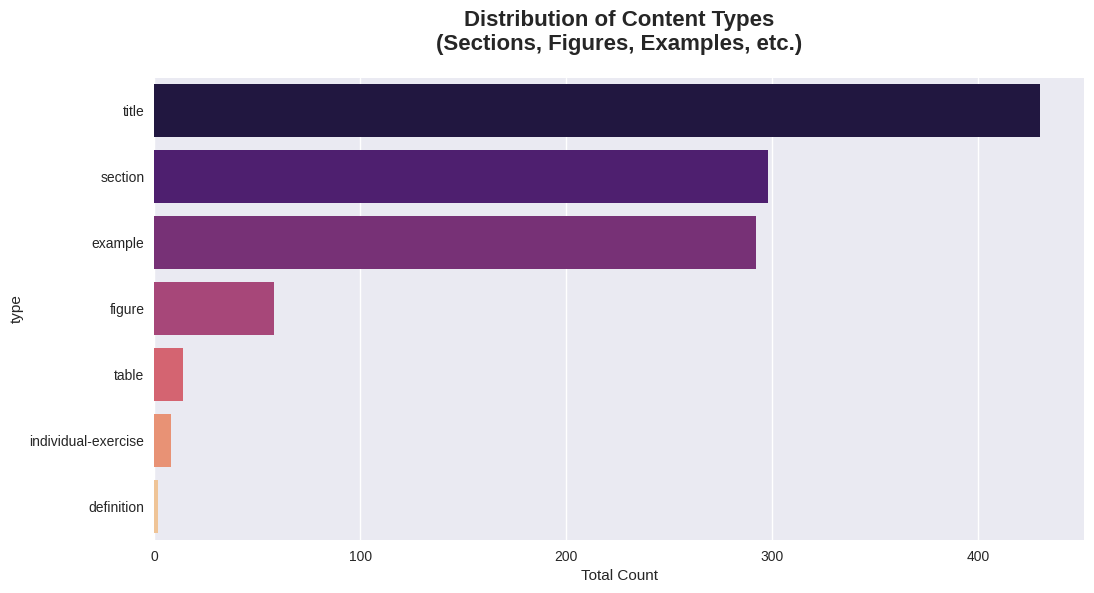

In [92]:
# Graph 3: Content Types
plt.figure(figsize=(12, 6))
type_counts = df['type'].value_counts()
sns.barplot(x=type_counts.values, y=type_counts.index, hue=type_counts.index, palette='magma', legend=False)
plt.title('Distribution of Content Types\n(Sections, Figures, Examples, etc.)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Total Count')
plt.show()


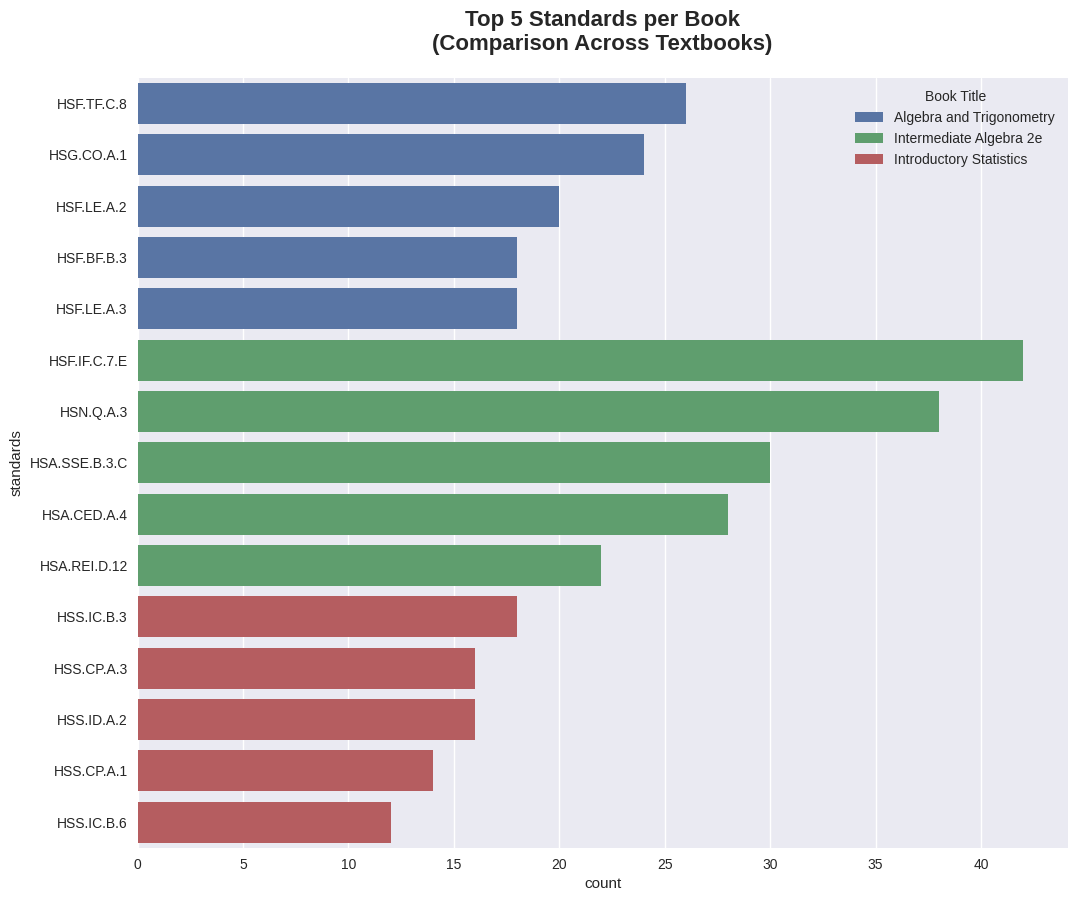

In [93]:
# Graph 4: Top 5 Standards per Book
plt.figure(figsize=(12, 10))
top_per_book = df_exploded.groupby('book')['standards'].value_counts().groupby(level=0).head(5).reset_index(name='count')
sns.barplot(data=top_per_book, x='count', y='standards', hue='book')
plt.title('Top 5 Standards per Book\n(Comparison Across Textbooks)', fontsize=16, fontweight='bold', pad=20)
plt.legend(title='Book Title', bbox_to_anchor=(1, 1))
plt.show()

In [94]:
import plotly.graph_objects as go

# 1. Prepare data for Sankey (Source -> Target)
# Flow A: Book Title to Content Type
flow1 = df.groupby(['book', 'type']).size().reset_index(name='count')
# Flow B: Content Type to Standards (Top 10 only for readability)
top_10_stds = df_exploded['standards'].value_counts().nlargest(10).index
df_filtered = df_exploded[df_exploded['standards'].isin(top_10_stds)]
flow2 = df_filtered.groupby(['type', 'standards']).size().reset_index(name='count')

# 2. Create Unique Label List
labels = list(pd.concat([flow1['book'], flow1['type'], flow2['standards']]).unique())
label_map = {label: i for i, label in enumerate(labels)}

# 3. Define Sources, Targets, and Values
source = [label_map[x] for x in flow1['book']] + [label_map[x] for x in flow2['type']]
target = [label_map[x] for x in flow1['type']] + [label_map[x] for x in flow2['standards']]
values = list(flow1['count']) + list(flow2['count'])

# 4. Create Figure
fig = go.Figure(data=[go.Sankey(
    node=dict(pad=15, thickness=20, line=dict(color="black", width=0.5), label=labels, color="skyblue"),
    link=dict(source=source, target=target, value=values)
)])

display(HTML("<h2 style='text-align: center;'>🗺️ DATA HIERARCHY FLOW 🗺️</h2>"))
fig.update_layout(title_text="Flow: Book → Content Type → Top 10 Standards", font_size=12, height=600)
fig.show()

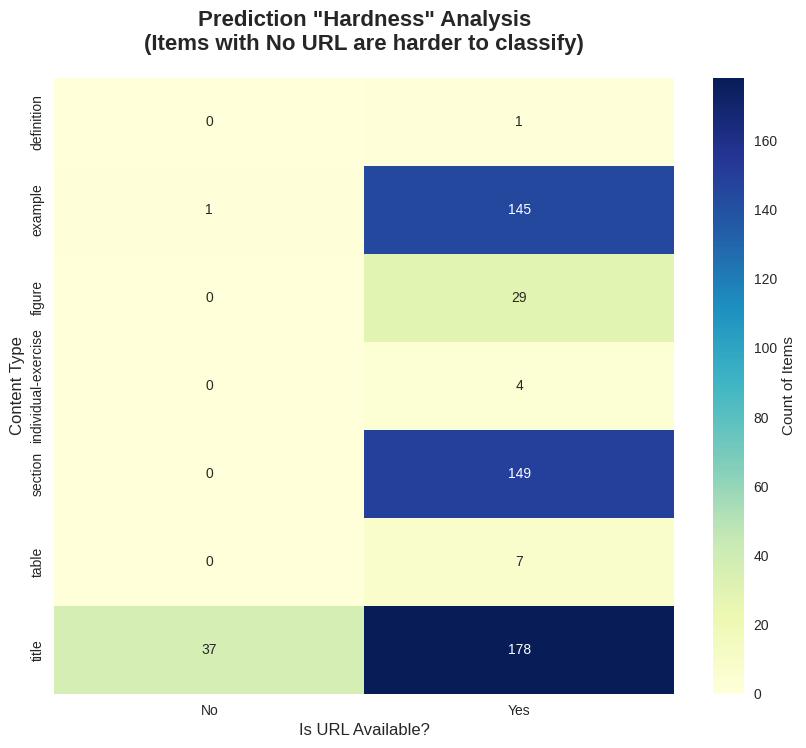

In [ ]:
# heatmap

heatmap_data = df_hard.groupby(['type', 'has_url']).size().unstack(fill_value=0)

plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data, annot=True, fmt='d', cmap='YlGnBu', cbar_kws={'label': 'Count of Items'})

plt.title('Prediction "Hardness" Analysis\n(Items with No URL are harder to classify)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Is URL Available?', fontsize=12)
plt.ylabel('Content Type', fontsize=12)

# Centering the output
display(HTML("<div style='display: flex; justify-content: center;'>"))
plt.show()
display(HTML("</div>"))

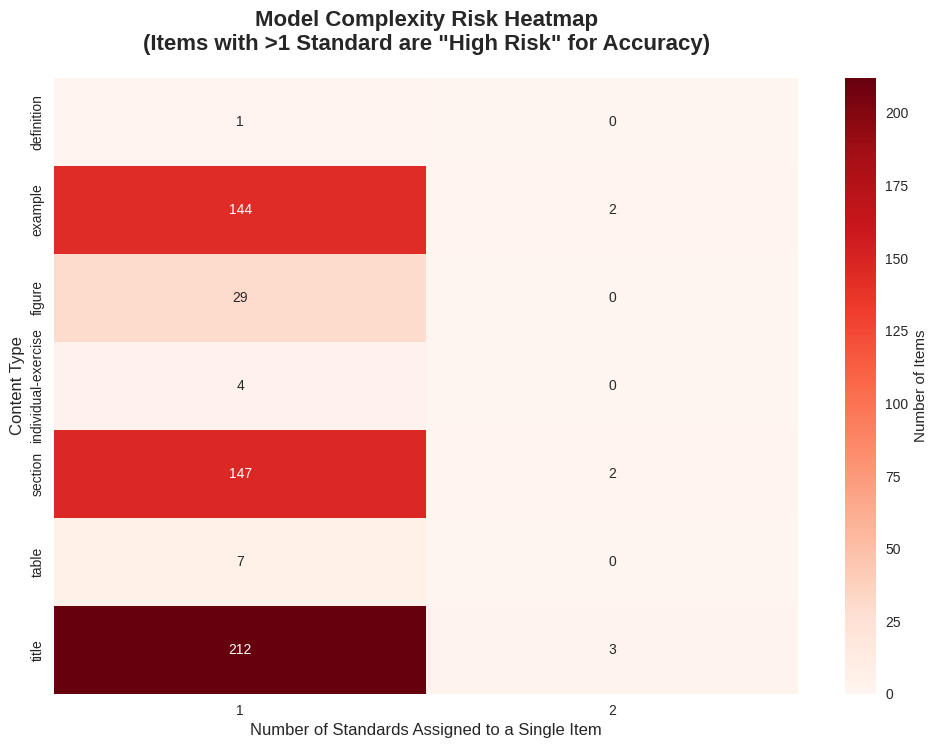

In [ ]:
comp_pivot = df_comp.groupby(['type', 'std_count']).size().unstack(fill_value=0)

# 3. Visualization
plt.figure(figsize=(12, 8))
sns.heatmap(comp_pivot, annot=True, fmt='d', cmap='Reds', cbar_kws={'label': 'Number of Items'})

plt.title('Model Complexity Risk Heatmap\n(Items with >1 Standard are "High Risk" for Accuracy)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Number of Standards Assigned to a Single Item', fontsize=12)
plt.ylabel('Content Type', fontsize=12)

# Centering the output
display(HTML("<div style='display: flex; justify-content: center;'>"))
plt.show()
display(HTML("</div>"))